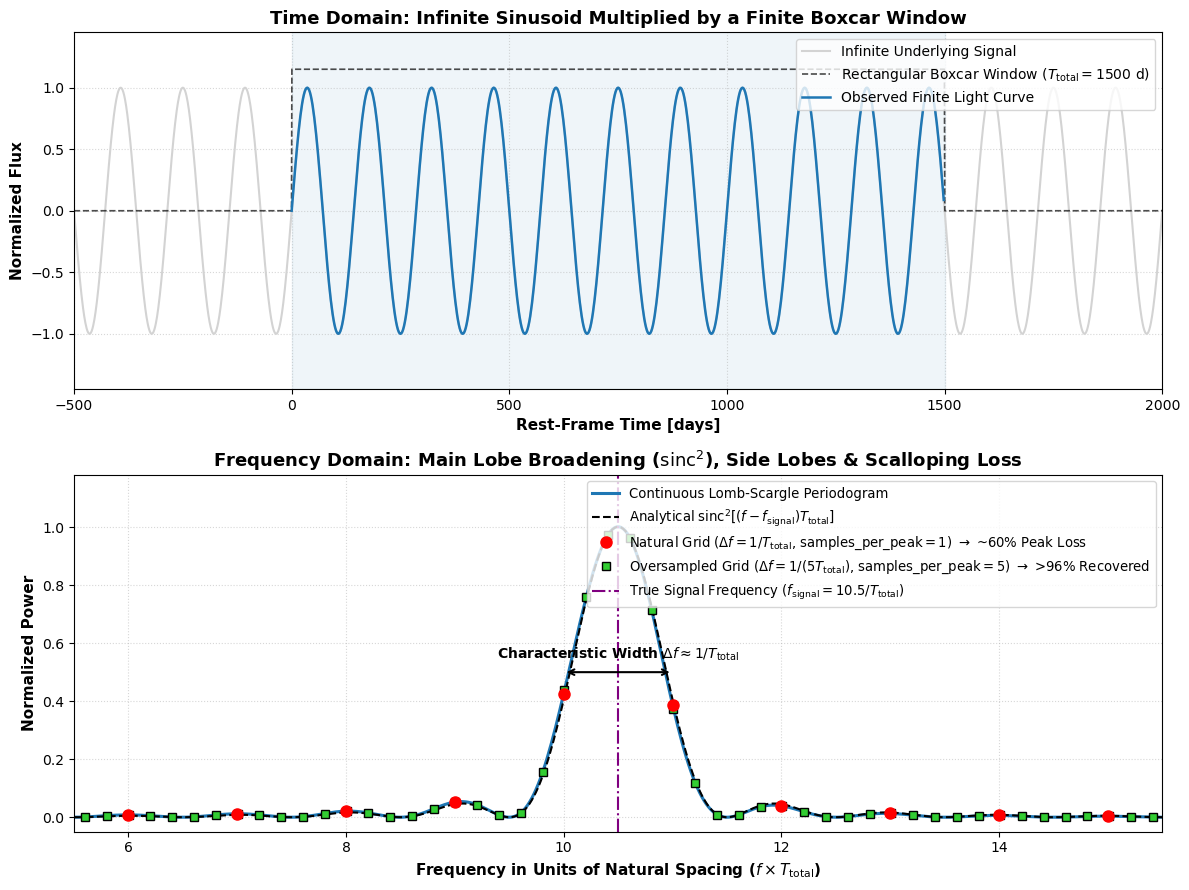

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

# 1. SIMULATION PARAMETERS (ZTF-like rest-frame baseline)
T_total = 1500.0  # Total observing baseline [days]
dt = 2.0          # Sampling cadence [days]

# Choose a signal frequency halfway between natural Fourier frequencies (10.5 / T_total)
# to clearly illustrate both the sinc^2 main lobe and scalloping loss
k_signal = 10.5
f_signal = k_signal / T_total  # ~0.007 day^-1 (Period ~ 142.8 days)

# 2. TIME DOMAIN: Infinite signal vs. Finite Rectangular (Boxcar) Window
t_extended = np.linspace(-600, T_total + 600, 3000)
y_infinite = np.sin(2.0 * np.pi * f_signal * t_extended)

# Rectangular window: 1 inside [0, T_total], 0 outside
window = np.where((t_extended >= 0) & (t_extended <= T_total), 1.0, 0.0)

# Observed discrete light curve inside [0, T_total]
t_obs = np.arange(0, T_total, dt)
y_obs = np.sin(2.0 * np.pi * f_signal * t_obs)

# 3. FREQUENCY DOMAIN: Periodogram & Theoretical sinc^2 Envelope
ls = LombScargle(t_obs, y_obs)

# High-resolution curve to trace the continuous sinc^2 shape
f_dense, p_dense = ls.autopower(
    normalization='standard',
    minimum_frequency=5.0 / T_total,
    maximum_frequency=16.0 / T_total,
    samples_per_peak=50
)

# Natural Fourier grid spacing: df = 1 / T_total (samples_per_peak = 1)
f_nat = np.arange(5, 17) / T_total
p_nat = ls.power(f_nat, normalization='standard')

# Standard oversampled grid: df = 1 / (5 * T_total) (samples_per_peak = 5)
f_spp5, p_spp5 = ls.autopower(
    normalization='standard',
    minimum_frequency=5.0 / T_total,
    maximum_frequency=16.0 / T_total,
    samples_per_peak=5
)

# Exact analytical power spectrum of a finite boxcar window: sinc^2((f - f_signal) * T_total)
# Note: np.sinc(x) = sin(pi * x) / (pi * x)
p_sinc2 = np.max(p_dense) * (np.sinc((f_dense - f_signal) * T_total) ** 2)

# 4. PLOTTING
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

# --- Top Panel: Time Domain ---
ax1.plot(t_extended, y_infinite, color='lightgray', lw=1.5, label='Infinite Underlying Signal')
ax1.plot(t_extended, window * 1.15, 'k--', lw=1.2, alpha=0.7, label=f'Rectangular Boxcar Window ($T_{{\\rm total}} = {int(T_total)}$ d)')
ax1.plot(t_obs, y_obs, color='tab:blue', lw=1.8, label='Observed Finite Light Curve')
ax1.axvspan(0, T_total, color='tab:blue', alpha=0.07)

ax1.set_xlim(-500, T_total + 500)
ax1.set_ylim(-1.45, 1.45)
ax1.set_xlabel('Rest-Frame Time [days]', fontweight='bold', fontsize=11)
ax1.set_ylabel('Normalized Flux', fontweight='bold', fontsize=11)
ax1.set_title('Time Domain: Infinite Sinusoid Multiplied by a Finite Boxcar Window', fontweight='bold', fontsize=13)
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(ls=':', alpha=0.5)

# --- Bottom Panel: Frequency Domain ---
ax2.plot(f_dense * T_total, p_dense, color='tab:blue', lw=2.2, label='Continuous Lomb-Scargle Periodogram')
ax2.plot(f_dense * T_total, p_sinc2, 'k--', lw=1.5, label=r'Analytical $\mathrm{sinc}^2[(f - f_{\rm signal}) T_{\rm total}]$')

# Compare samples_per_peak=1 vs samples_per_peak=5
ax2.plot(f_nat * T_total, p_nat, 'ro', ms=8, zorder=5,
         label=r'Natural Grid ($\Delta f = 1/T_{\rm total}$, $\mathrm{samples\_per\_peak}=1$) $\rightarrow$ ~60% Peak Loss')
ax2.plot(f_spp5 * T_total, p_spp5, 's', color='limegreen', markeredgecolor='black', ms=6, zorder=4,
         label=r'Oversampled Grid ($\Delta f = 1/(5 T_{\rm total})$, $\mathrm{samples\_per\_peak}=5$) $\rightarrow$ >96% Recovered')

# Highlight true signal frequency and first nulls (f_signal +/- 1/T_total)
ax2.axvline(k_signal, color='purple', ls='-.', lw=1.5, label=f'True Signal Frequency ($f_{{\\rm signal}} = {k_signal}/T_{{\\rm total}}$)')
ax2.annotate(
    '', xy=(k_signal - 0.5, 0.5), xytext=(k_signal + 0.5, 0.5),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.5)
)
ax2.text(k_signal, 0.53, r'Characteristic Width $\Delta f \approx 1/T_{\rm total}$',
         ha='center', va='bottom', fontweight='bold', fontsize=10)

ax2.set_xlim(5.5, 15.5)
ax2.set_ylim(-0.05, 1.18)
ax2.set_xlabel(r'Frequency in Units of Natural Spacing ($f \times T_{\rm total}$)', fontweight='bold', fontsize=11)
ax2.set_ylabel('Normalized Power', fontweight='bold', fontsize=11)
ax2.set_title(r'Frequency Domain: Main Lobe Broadening ($\mathrm{sinc}^2$), Side Lobes & Scalloping Loss', fontweight='bold', fontsize=13)
ax2.legend(loc='upper right', fontsize=9.5)
ax2.grid(ls=':', alpha=0.5)

plt.tight_layout()
plt.show()